In [1]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import util
import scipy as sp
import matplotlib.pyplot as plt
import tqdm
from matplotlib.lines import Line2D

# from util import evolve

In [2]:
folder = '../Data/'
# df_AM22 = pd.read_excel(folder+"Armstrong McKay 2022/science.abn7950_data_s1.xlsx",
#                         skiprows=[0,1,2,3,4],sheet_name='4) Estimates',
#                         skipfooter=40,index_col=1,header=[0,1])
df_TEs = pd.read_excel(folder+'TEsummary.xlsx',header=[0],index_col=0)

df_TEs.head()

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN


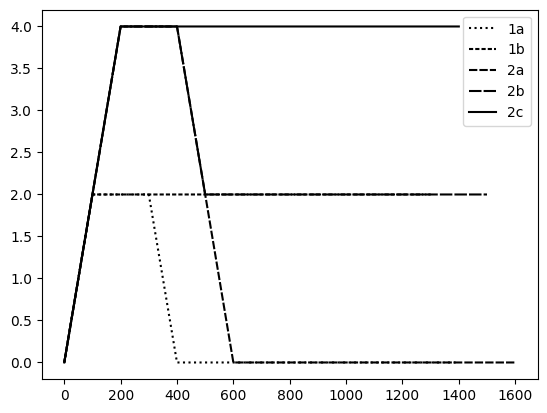

In [3]:
# Scenarios:
    # 1) Ramp up to 2C, stabilise for 200y @ 2C
        # 1a) Ramp down to 0, stabilise for another 1ky
        # 1b) Remain at 2C, stabilise for another 1ky
    # 2) Ramp up to 4C, stabilise for 200y @ 4C
        # 2a) Ramp down to 0, stabilise for another 1ky
        # 2b) Ramp down to 2C, stabilise for another 1ky
        # 2c) Remain at 4C, stabilise for another 1ky
scenarios = ['1a','1b','2a','2b','2c']
temps = {}
temps['1a'] = np.concatenate((np.arange(0,2.01,step=0.02),
                              np.ones(200)*2,
                              np.arange(0,2,step=0.02)[::-1], 
                              np.zeros(1000)) 
                            )
temps['1b'] = np.concatenate((np.arange(0,2.01,step=0.02),
                         np.ones(1200)*2))
# temps['1c'] = np.concatenate((np.arange(0,2.01,step=0.02),
#                          np.ones(1200)*2,
#                          np.arange(0,2,step=0.02)[::-1]))

temps['2a'] = np.concatenate((np.arange(0,4.01,step=0.02),
                              np.ones(200)*4,
                              np.arange(0,4,step=0.02)[::-1],
                              np.zeros(1000)))
temps['2b'] = np.concatenate((np.arange(0,4.01,step=0.02),
                              np.ones(200)*4,
                              np.arange(2,4,step=0.02)[::-1],
                              np.ones(1000)*2))
temps['2c'] = np.concatenate((np.arange(0,4.01,step=0.02),
                         np.ones(1200)*4))
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
for i,s in enumerate(scenarios):
    # if s=='2b':
    #     continue
    plt.plot(temps[s],label=s,color='k',ls=linestyles[i])
plt.legend()

In [4]:
folder = "../Data/Interaction matrices/"
no_samples = 500
A = [np.loadtxt(folder+'A_'+str(r)+'.csv') for r in range(no_samples)]

In [5]:
D = {s: np.array([util.evolve(np.zeros(9), A[r], len(temps[s]),
                 tau_c = df_TEs['Collapse (years)'].to_numpy(),
                 tau_r = df_TEs['Recovery (years)'].to_numpy(),
                 T = temps[s],
                 beta=df_TEs['Beta (1/°C)'].to_numpy(),
                 T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy()) for r in tqdm.tqdm(range(no_samples))]) 
     for s in scenarios}

100%|█████████████████████████████████████████| 500/500 [00:05<00:00, 94.04it/s]


In [6]:
start_points = {'1a':len(np.concatenate((np.arange(0,2.01,step=0.02),
                                         np.ones(200)*2))),
                '1b':0,
                '2a':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2,
                                         np.arange(2,4,step=0.02)[::-1]))), 
                '2b':len(np.concatenate((np.arange(0,4.01,step=0.02),
                                         np.ones(200)*2))),
                '2c':0}

## plotting

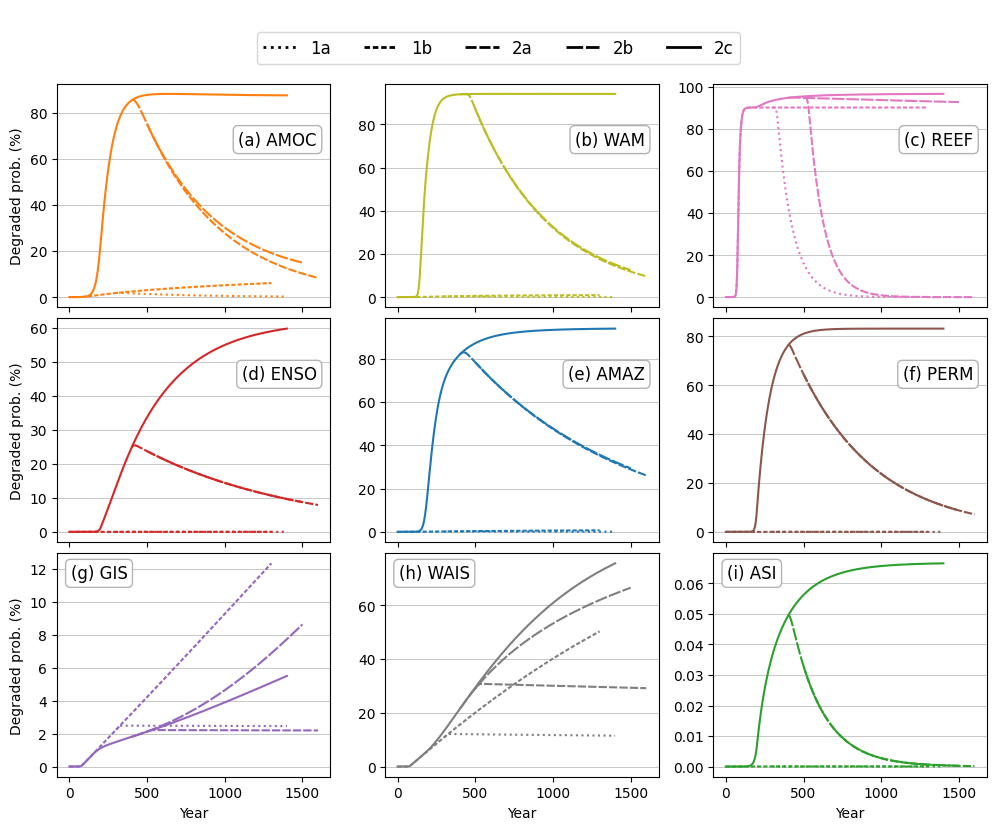

In [19]:
TEs = ['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS', 'WAM']
TE_ordered = ['AMOC', 'WAM', 'REEF',
              'ENSO', 'AMAZ','PERM',
              'GIS', 'WAIS', 'ASI']
TE_ind = {te:i for i,te in enumerate(TEs)}

# locs = [(0.95,0.5),(0.95,0.5),(0.95,0.5), ]
locs = [(0.95,0.75)]*6 + [(0.05,0.95)]*3
has = ['right']*6 + ['left']*3
vas= ['center']*6 + ['top']*3
fig,axs = util.TE_9x9_fig(TE_ordered=TE_ordered, subfig_lab_loc=locs,ha=has,va=vas,fontsize=12)
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
linestyles = [':'] + [(0,(2*j+2,1)) for j in range(len(scenarios)-2)] + ['-']
# linestyles = linestyles[::-1]

for i_ax,te in enumerate(TE_ordered):
    i = TE_ind[te]
    for j,s in enumerate(scenarios):
        # util.ribbon_plot(axs[i_ax//3,i_ax%3], 
        #                  range(start_points[s],len(temps[s])), 
        #                  D[s][:,i,start_points[s]:]*100, 
        #                  color=util.lighten_color(colors[i],1),axis=0,
        #                  alpha=[0.3],)
        axs[i_ax//3,i_ax%3].plot(range(start_points[s],len(temps[s])),
                                 D[s][:,i,start_points[s]:].mean(axis=0)*100,
                                 c=util.lighten_color(colors[i],1),#0.1+(j+3)/(len(scenarios)+3)), 
                                 ls=linestyles[j],
                                 lw=1.5)

lines = [Line2D([0], [0], color=util.lighten_color('k',1),#0.1+(j+3)/(len(scenarios)+3)), 
                lw=2, 
                label=scenarios[j], 
                ls = linestyles[j]) 
         for j in range(len(scenarios))]
fig.legend(handles=lines,ncols=len(scenarios),loc='upper center',
           prop={'size':12},borderaxespad=2)

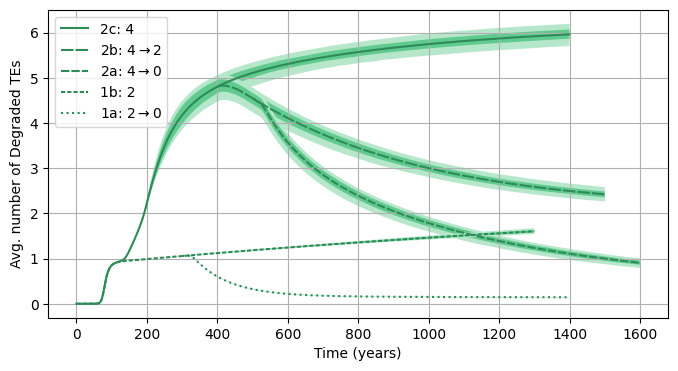

In [37]:
fig,ax = plt.subplots(figsize=(8,4))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    util.ribbon_plot(ax, 
                     range(start_points[s],len(temps[s])), 
                     D[s][:,:,start_points[s]:].sum(axis=1), 
                     color='seagreen',axis=0,
                     alpha=[1]*2,quantiles=[0.05,0.25],shade=[0.3,0.65])
    ax.plot(range(start_points[s],len(temps[s])),
            D[s][:,:,start_points[s]:].sum(axis=1).mean(axis=0),
            color=util.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    # ax.fill_between(years, 
    #              np.quantile(D[j,:,:,:].sum(axis=1),0.25,axis=0),
    #              np.quantile(D[j,:,:,:].sum(axis=1),0.75,axis=0),
    #                 # lighten_color by 0.65
    #              color=util.lighten_color(colors[j],1),
    #              edgecolor=util.lighten_color(colors[j],1),
    #              alpha=0.6)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Avg. number of Degraded TEs')
ax.set_xlabel('Time (years)')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')

# including warming feedbacks

In [42]:
def evolve_feedback(D_init, A, no_time_steps, 
           order_ST=True, 
           pc = None, tau_c = None, 
           T = None, beta = None, T_lim = None,
           pr = None, tau_r = None, impact = None
           ):
    """ 
    Wrapper to evolve system up to and including t = no_time_steps, 
    with an initial value of D_init at time t=0, taking into account the warming feedbacks due to tipping impacts.

    Parameters (required)
    ---
    D_init : numpy.array
        The initial array of degraded probabilities at time step 0
    A : numpy.array
        The interaction matrix (i.e. adjacency matrix), must be of shape (len(D_init), len(D_init)). 
        No self loops, i.e. all diagonal elements should be 0. 
    no_time_steps : int
        The number of time steps to simulate over, 
        i.e. the number of times the update equation is successively applied. 
        Must be >= 1
    
    Parameters (optional):
    order_ST : Bool
        The indexing order of the adjacent matrix. 
        If True, then the adjacency matrix will be read with an index-order that gives A[source, target].
        Otherwise the order will be assumed as A[target, source]
        Default True.
    pc : numpy.array or something broadcastable
        The array/list/collection of collapse rates (without interactions). 
        Will supercede any calls to tau_c or T
        Must be in [0,1]. 
    tau_c :  numpy.array or something broadcastable
        The array/list/collection of collapse time scales. 
    T : array-like
        The global temperature(s) at which to evaluate. 
        Must be of length >= no_time_steps. Must have beta and T_lim supplied as well if not None
    beta : array-like or float
        Temperature sensitivities (i.e. logistic parameters) for individual tipping points.
        If array-like must be of length len(D_init). 
    T_lim : array-like or float
        Critical temperature thresholds for individual tipping points.
        If array-like must be of length len(D_init)
    pr : numpy.array or something broadcastable
        The array/list/collection of collapse rates. Will supercede tau_r
    tau_r : numpy.array or something broadcastable
        The array/list/collection of collapse time scales
    impact: numpy.array
        The array of maximum (in absolute) warming impacts for each element tipping.
        Must be of length len(D_init)
    
        
    Returns
    ---
    D_out : numpy.array
        The output will be a (len(D_init), no_time_steps+1)-shaped array where the D_out[:,0] = D_init
    Examples
    ---
    """
    ## Initialising D_out
    D_out = np.zeros((len(D_init), no_time_steps))
    D_out[:,0] = D_init
    T_out = T
    
    ## Changing pc if needed
    if pc is None:
        if tau_c is None:
            raise ValueError("No collapse time scales given")
            pc = np.ones(len(D_init))/2 ## if nothing is supplied pc will be set to 1/2
        else:
            # if any of T,T_lim,beta are None, then pc = 1/(tau_c+1)
            pc = np.ones((len(D_init), no_time_steps))/(tau_c.reshape(len(D_init),1)+1)
        # else:
        #     pc = np.ones((len(D_init), no_time_steps))
        #     pc /= (tau_c.reshape(len(D_init),1)+1)
        #     for t in range(no_time_steps):
        #         pc[:,t] *= temp_response(T[t], T_lim, beta)
    if np.any(pc>1) or np.any(pc<0):
        raise ValueError("Collapse probability pc not in [0,1]")
    ## Changing pr if needed
    if pr is None:
        if tau_r is None:  
            raise ValueError("No recovery time scales given")
        else:
            pr = 1/(tau_r+1)
    if np.any(pr>1) or np.any(pr<0):
        raise ValueError("Recovery probability pr not in [0,1]")
    if order_ST:
        A = A.transpose()

    for t in range(1,no_time_steps):
        T_out[t-1] += np.dot(D_out[:,t],impact)
        pc[:,t-1] *= util.temp_response(T_out[t-1], T_lim, beta)
        D_out[:,t] = util.environmental_update(D_out[:,t-1],A,pc[:,t-1],pr)

    return D_out,T_out

In [55]:
df_TEs

,Tipping element,Collapse (years),Recovery (years),Threshold (°C) – Min.,Threshold (°C) – Est.,Threshold (°C) – Max.,Beta (1/°C),Max Impact (°C) – Global,Comments
TE,,,,,,,,,
AMAZ,Amazon rainforest dieback,100,1000,2.0,3.5,6.0,4.604503,0.20,"Max impact for a total die back is 0.2C, while..."
AMOC,Atlantic meridional ocean circulation,50,500,1.4,4.0,8.0,2.656444,-0.50,NaN
ASI,Arctic winter sea ice,20,200,4.5,6.3,8.7,3.837086,0.60,NaN
ENSO,El Nino Southern Oscillation,100,1000,3.0,4.5,6.0,4.604503,0.00,From Armstrong McKay et al no estimate for max...
GIS,Greenland ice sheet,10000,100000,0.8,1.5,3.0,9.866793,0.13,NaN
PERM,Boreal permafrost collapse,50,500,3.0,4.0,6.0,6.906755,0.30,From Armstrong McKay 2022 max impact is estima...
REEF,Low-latitude coral reefs,10,100,1.0,1.5,2.0,13.813510,0.00,From Armstrong McKay et al no estimate for max...
WAIS,West Antarctic ice sheet,2000,20000,1.0,1.5,3.0,13.813510,0.05,NaN
WAM,Sahel and West African monsoon,50,500,2.0,2.8,3.5,8.633443,0.00,From Armstrong McKay et al no estimate for max...


In [43]:
outputs = {s: [evolve_feedback(np.zeros(9), A[r], len(temps[s]),
                               tau_c = df_TEs['Collapse (years)'].to_numpy(),
                               tau_r = df_TEs['Recovery (years)'].to_numpy(),
                               T = temps[s],
                               beta=df_TEs['Beta (1/°C)'].to_numpy(),
                               T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy(),
                               impact= df_TEs['Max Impact (°C) – Global'].to_numpy()) 
               for r in tqdm.tqdm(range(no_samples))] 
     for s in scenarios}

100%|█████████████████████████████████████████| 500/500 [00:05<00:00, 85.10it/s]


In [45]:
len(outputs['1a'][0])

2

In [47]:
D_impact = {s:np.array([outputs[s][r][0] for r in range(no_samples)]) for s in scenarios}
T_impact = {s:np.array([outputs[s][r][1] for r in range(no_samples)]) for s in scenarios}

/tmp/ipykernel_14551/3493520443.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


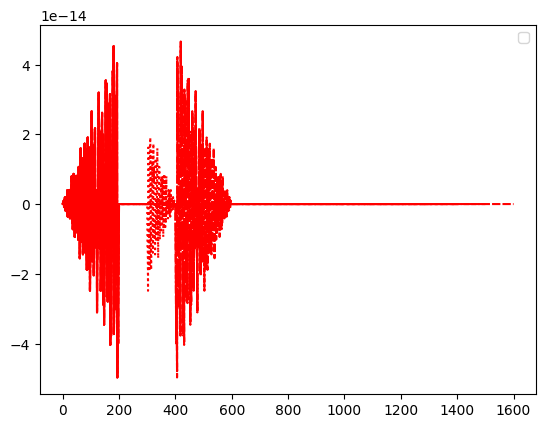

In [54]:
for i,s in enumerate(scenarios):
    # if s=='2b':
    #     continue
    # plt.plot(temps[s],label=s,color='k',ls=linestyles[i])
    plt.plot(temps[s]-T_impact[s].mean(axis=0),color='r',ls=linestyles[i])
plt.legend()

In [56]:
D['1a'].shape

(500, 9, 1401)

In [60]:
T_no_feedback = {s:np.array([np.dot(D[s][:,:,t],df_TEs['Max Impact (°C) – Global'].to_numpy()) 
                             for t in range(len(temps[s]))]) 
                 for s in scenarios}

In [61]:
T_no_feedback['1a'].shape

(1401, 500)

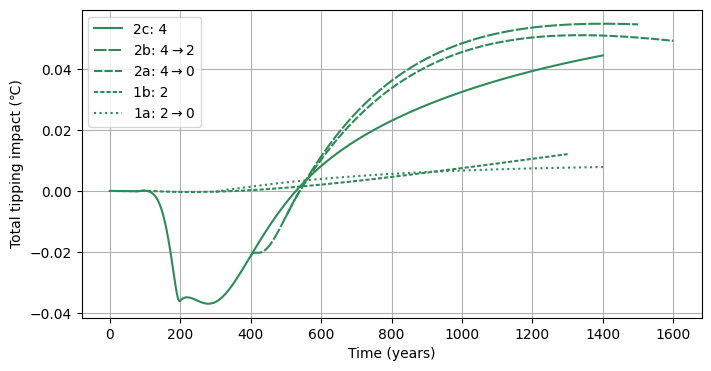

In [65]:
fig,ax = plt.subplots(figsize=(8,4))
labels = [r'2$\rightarrow$0', '2', r'4$\rightarrow$0', r'4$\rightarrow$2', '4']
for j,s in enumerate(scenarios[::-1]):
    # util.ribbon_plot(ax, 
    #                  range(start_points[s],len(temps[s])), 
    #                  T_no_feedback[s][start_points[s]:,:], 
    #                  color='seagreen',axis=1,
    #                  alpha=[0.5]*2,quantiles=[0.05,0.25],shade=[0.3,0.65])
    ax.plot(range(start_points[s],len(temps[s])),
            T_no_feedback[s][start_points[s]:,:].mean(axis=1),
            color=util.lighten_color('seagreen',1),label=s+': '+labels[::-1][j],ls=linestyles[::-1][j])
    # ax.fill_between(years, 
    #              np.quantile(D[j,:,:,:].sum(axis=1),0.25,axis=0),
    #              np.quantile(D[j,:,:,:].sum(axis=1),0.75,axis=0),
    #                 # lighten_color by 0.65
    #              color=util.lighten_color(colors[j],1),
    #              edgecolor=util.lighten_color(colors[j],1),
    #              alpha=0.6)
    # ax.plot(years,D_noint[j,:,:].sum(axis=0),
    #                          c=util.lighten_color(colors[j],1), 
    #                          ls='--',lw=1)

ax.grid()
# ax.set_xlim([1850,2350])
ax.set_ylabel('Total tipping impact (℃)')
ax.set_xlabel('Time (years)')

# ax_temp = ax.inset_axes([1850, 1, 170, 3.5], transform=ax.transData)
# ax_temp.yaxis.tick_right()
# ax_temp.set_xlim([1850,2350])
# ax_temp.set_xticks([1900,2100,2300])
# ax_temp.tick_params(axis='both', which='major', labelsize=8)
# for j,s in enumerate(scenarios):
#     # ax_temp.fill_between(years, dfs[s][0.05],dfs[s][0.95],alpha=0.1,color=colors[i])
#     ax_temp.plot(years,dfs[s]['mean'].to_numpy(), color=colors[j])

legend=plt.legend(loc='upper left',ncols=1)
# fig.savefig(folder_out+'ES_extendedSSPs.pdf',format='pdf',dpi=300,bbox_inches='tight')